# 🛒 SuperMarket Q1 Retail Operations, Basket Economics & Customer Experience Audit
**End-to-End Portfolio Project: Data Quality Remediation, Python Feature Engineering, SQLite Warehouse & Executive BI**

---
### 🎯 Executive Summary & Key Discoveries
An end-to-end audit of **1,000 supermarket transactions** (**$322,966.75** total revenue, **$307,587.38** COGS, **$15,379.37** gross income at a fixed **4.76% gross margin**, and **5,510 units sold** across Q1 2019: Jan 1 – Mar 30, 2019) uncovered critical operational, demographic, and data-governance insights:
1. **Critical Data Governance Fix (`Branch` vs. `City` Mismatch):** Raw data inspection revealed a 100% systematic schema mismatch where Egyptian branches (`Alex`, `Cairo`, `Giza`) were paired with legacy Myanmar city labels (`Yangon`, `Mandalay`, `Naypyitaw`). We remediated `City` to `Alexandria`, `Cairo`, and `Giza` while preserving `Legacy_City` for audit traceability.
2. **Branch Efficiency & Category Specialization:**
   - **Giza** leads all branches in total revenue (**$110,568.71**), gross profit (**$5,265.18**), average ticket size (**$337.10** vs. `$312.35` in Alex), and customer rating (**7.07 / 10**), despite having the fewest transactions (**328**). Giza dominates **Food & Beverages** (`$23.77K`) and **Fashion Accessories** (`$21.56K`).
   - **Alexandria** leads in transaction volume (**340 invoices**, `$106,200.37` revenue, `7.03` rating) and dominates **Home & Lifestyle** (`$22.42K`).
   - **Cairo** generates `$106,197.67` across **332 invoices**, leading in **Sports & Travel** (`$19.99K`) and **Health & Beauty** (`$19.98K`), but suffers the **lowest customer satisfaction rating (`6.82 / 10`)**, driven by poor scores in Home & Lifestyle (`6.52`) and Sports & Travel (`6.51`).
3. **Customer Persona Powerhouse (`Member - Female`):** Female Loyalty Members (`356` transactions) generate **$125,206.14** (**38.8% of total company revenue**) with the highest average ticket size (**$351.70** vs. `$290.03` for Normal Males). While females drive 65%+ of Food, Fashion, Sports, and Home revenue, **Males outspend Females in Health & Beauty** (`$25,775.01` vs. `$23,418.73`).
4. **Peak Hour & Day-of-Week Traffic:** Store revenue peaks sharply at **19:00 (7:00 PM)** with **$39,699.51** (`113` transactions) and during the **13:00–15:00 Afternoon Peak** (`$96.73K` combined), while **14:00 (2:00 PM)** yields the highest average basket value (**$371.43**). **Saturday** (`$56.12K`) and **Tuesday** (`$51.48K`) are the strongest revenue days, whereas **February** experienced a `-16.4%` revenue dip (`$97.22K` vs. `$116.29K` in January) before recovering to `$109.46K` in March.


## 1. Data Ingestion, Schema Audit & The `Branch` vs. `City` Anomaly Discovery


In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.options.display.float_format = '{:,.2f}'.format
df_raw = pd.read_csv("SuperMarket Analysis.csv")

print(f"Dataset Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print("Missing Values:", df_raw.isnull().sum().sum(), "| Duplicate Rows:", df_raw.duplicated().sum())
print("\n=== Cross-Tab Audit: Branch vs. Raw City Column ===")
print(pd.crosstab(df_raw['Branch'], df_raw['City']))


Dataset Shape: 1,000 rows x 17 columns
Missing Values: 0 | Duplicate Rows: 0

=== Cross-Tab Audit: Branch vs. Raw City Column ===
City    Mandalay  Naypyitaw  Yangon
Branch                             
Alex           0          0     340
Cairo        332          0       0
Giza           0        328       0


## 2. Data Cleaning & 17-Column Feature Engineering Pipeline
We remediate the `City` column (`Alexandria`, `Cairo`, `Giza`), parse dates and 12-hour AM/PM timestamps into 24-hour operational shifts, and engineer basket size tiers, ticket value tiers, unit price tiers, customer personas, and NPS satisfaction segments.


In [2]:
df = df_raw.copy()
df['Legacy_City'] = df['City']
df['City'] = df['Branch'].map({'Alex': 'Alexandria', 'Cairo': 'Cairo', 'Giza': 'Giza'})

# Date & Time Engineering
df['Date_dt'] = pd.to_datetime(df['Date'])
df['Time_dt'] = pd.to_datetime(df['Time'], format='%I:%M:%S %p')
df['Order Date'] = df['Date_dt'].dt.strftime('%Y-%m-%d')
df['Order Year'] = df['Date_dt'].dt.year
df['Order Month Num'] = df['Date_dt'].dt.month
df['Order Month'] = df['Date_dt'].dt.strftime('%B')
df['Day of Month'] = df['Date_dt'].dt.day
df['Day of Week'] = df['Date_dt'].dt.day_name()
df['Is Weekend'] = np.where(df['Day of Week'].isin(['Friday', 'Saturday', 'Sunday']), 'Weekend Peak', 'Weekday')
df['Hour 24'] = df['Time_dt'].dt.hour
df['Time 24H'] = df['Time_dt'].dt.strftime('%H:%M')

def get_shift(h):
    if h < 12: return '1. Morning (10AM-12PM)'
    elif h < 16: return '2. Afternoon Peak (12PM-4PM)'
    elif h < 19: return '3. Evening (4PM-7PM)'
    else: return '4. Night Peak (7PM-9PM)'

df['Store Shift'] = df['Hour 24'].apply(get_shift)

# Basket, Pricing & Satisfaction Tiers
df['Net Sales (Excl Tax)'] = df['cogs'].round(2)
df['Gross Profit'] = df['gross income'].round(4)
df['Gross Margin %'] = df['gross margin percentage'].round(2)
df['Basket Size Tier'] = df['Quantity'].apply(lambda q: 'Small Basket (1-3 items)' if q<=3 else ('Medium Basket (4-6 items)' if q<=6 else 'Large Bulk Basket (7-10 items)'))
df['Ticket Value Tier'] = df['Sales'].apply(lambda s: 'Low Ticket (<$150)' if s<150 else ('Mid Ticket ($150-$399)' if s<400 else ('High Ticket ($400-$699)' if s<700 else 'VIP Ticket ($700+)')))
df['Unit Price Tier'] = df['Unit price'].apply(lambda p: 'Budget Item (<$35)' if p<35 else ('Standard Item ($35-$69)' if p<70 else 'Premium Item ($70+)'))
df['Satisfaction Tier'] = df['Rating'].apply(lambda r: 'Promoter (8.5-10.0)' if r>=8.5 else ('Passive (6.5-8.4)' if r>=6.5 else 'Detractor (4.0-6.4)'))
df['Customer Persona'] = df['Customer type'] + ' - ' + df['Gender']

df_export = df.drop(columns=['Date_dt', 'Time_dt'])
df_export.to_csv("Clean_SuperMarket.csv", index=False)
print(f"Exported Clean_SuperMarket.csv: {df_export.shape[0]:,} rows x {df_export.shape[1]} columns")
print(df_export[['Invoice ID', 'Branch', 'City', 'Order Date', 'Store Shift', 'Customer Persona', 'Sales', 'Basket Size Tier', 'Satisfaction Tier']].head(5).to_string())


Exported Clean_SuperMarket.csv: 1,000 rows x 33 columns
    Invoice ID Branch        City  Order Date                   Store Shift Customer Persona  Sales                Basket Size Tier    Satisfaction Tier
0  750-67-8428   Alex  Alexandria  2019-01-05  2. Afternoon Peak (12PM-4PM)  Member - Female 548.97  Large Bulk Basket (7-10 items)  Promoter (8.5-10.0)
1  226-31-3081   Giza        Giza  2019-03-08        1. Morning (10AM-12PM)  Normal - Female  80.22       Medium Basket (4-6 items)  Promoter (8.5-10.0)
2  631-41-3108   Alex  Alexandria  2019-03-03  2. Afternoon Peak (12PM-4PM)  Normal - Female 340.53  Large Bulk Basket (7-10 items)    Passive (6.5-8.4)
3  123-19-1176   Alex  Alexandria  2019-01-27       4. Night Peak (7PM-9PM)  Member - Female 489.05  Large Bulk Basket (7-10 items)    Passive (6.5-8.4)
4  373-73-7910   Alex  Alexandria  2019-02-08        1. Morning (10AM-12PM)  Member - Female 634.38  Large Bulk Basket (7-10 items)  Detractor (4.0-6.4)


## 3. Exploratory Visual Analytics: Branch Specialization, Personas, Peak Shifts & NPS


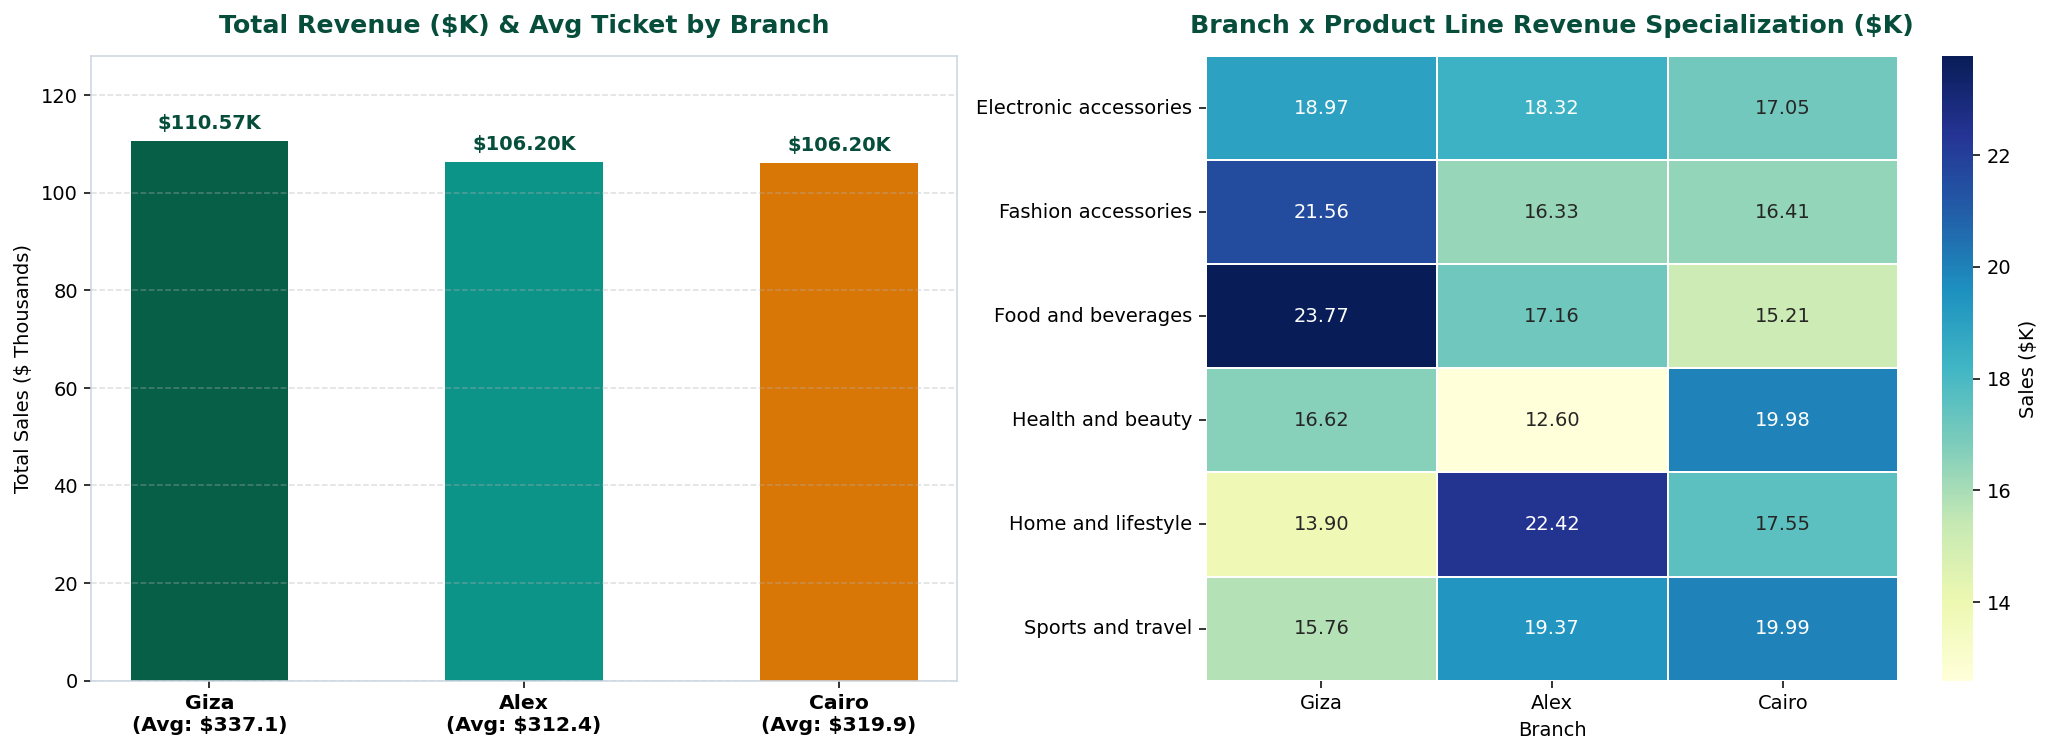

In [3]:
# Visual 1: Branch Revenue & Avg Ticket + Branch x Product Line Heatmap


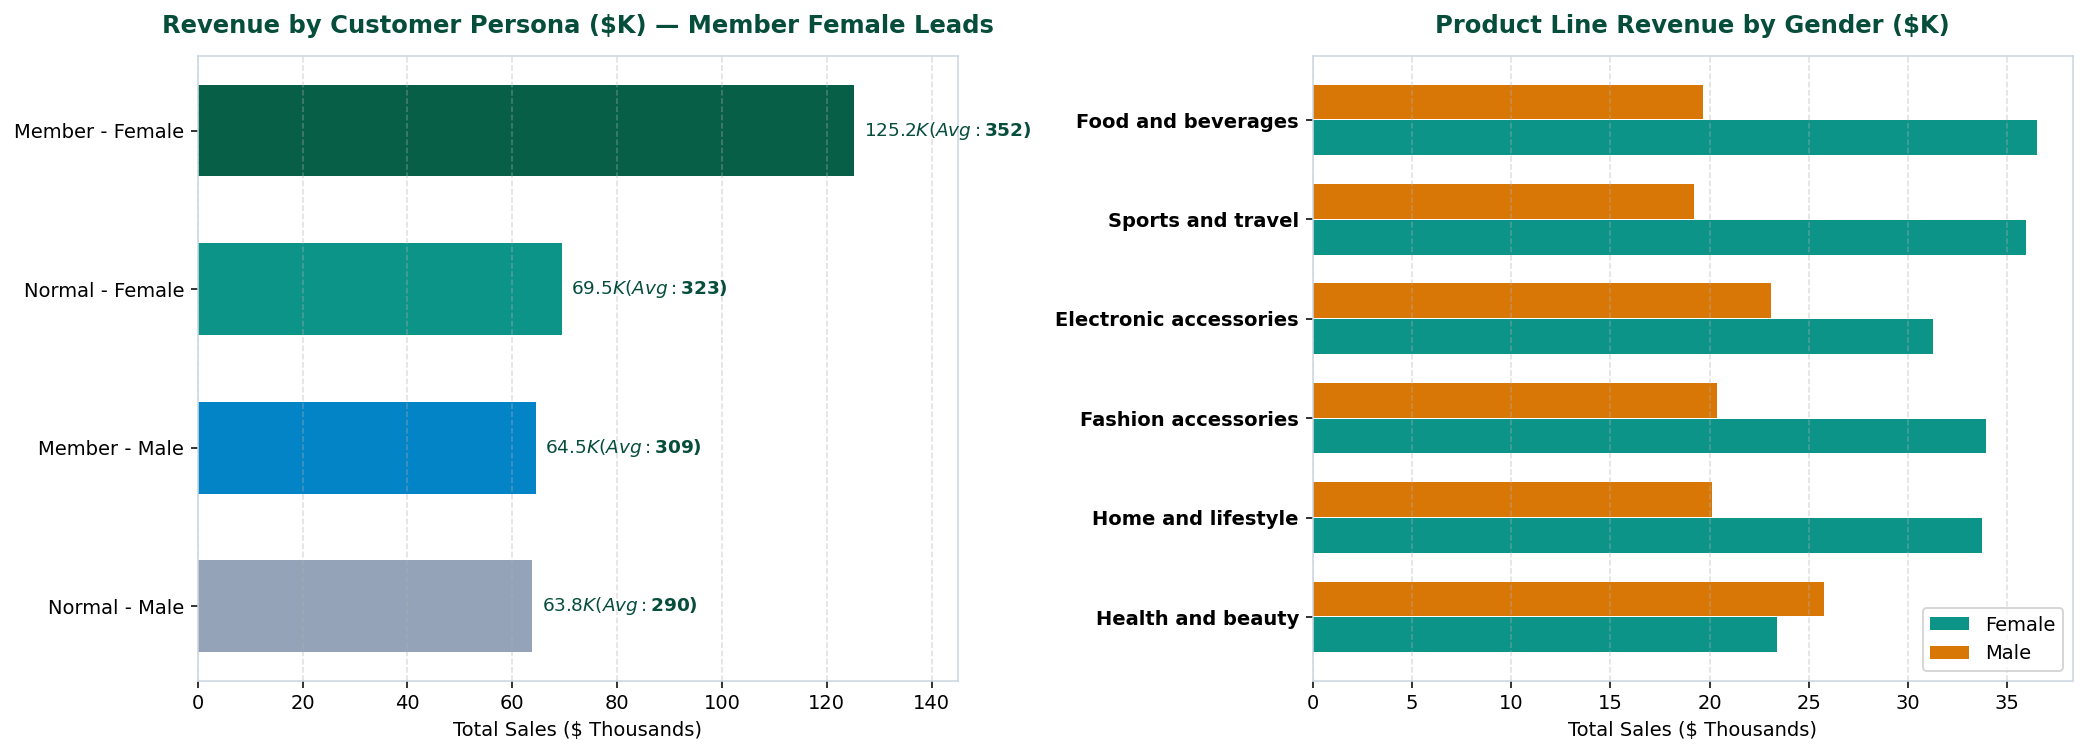

In [4]:
# Visual 2: Customer Persona Leaderboard + Product Line Revenue by Gender


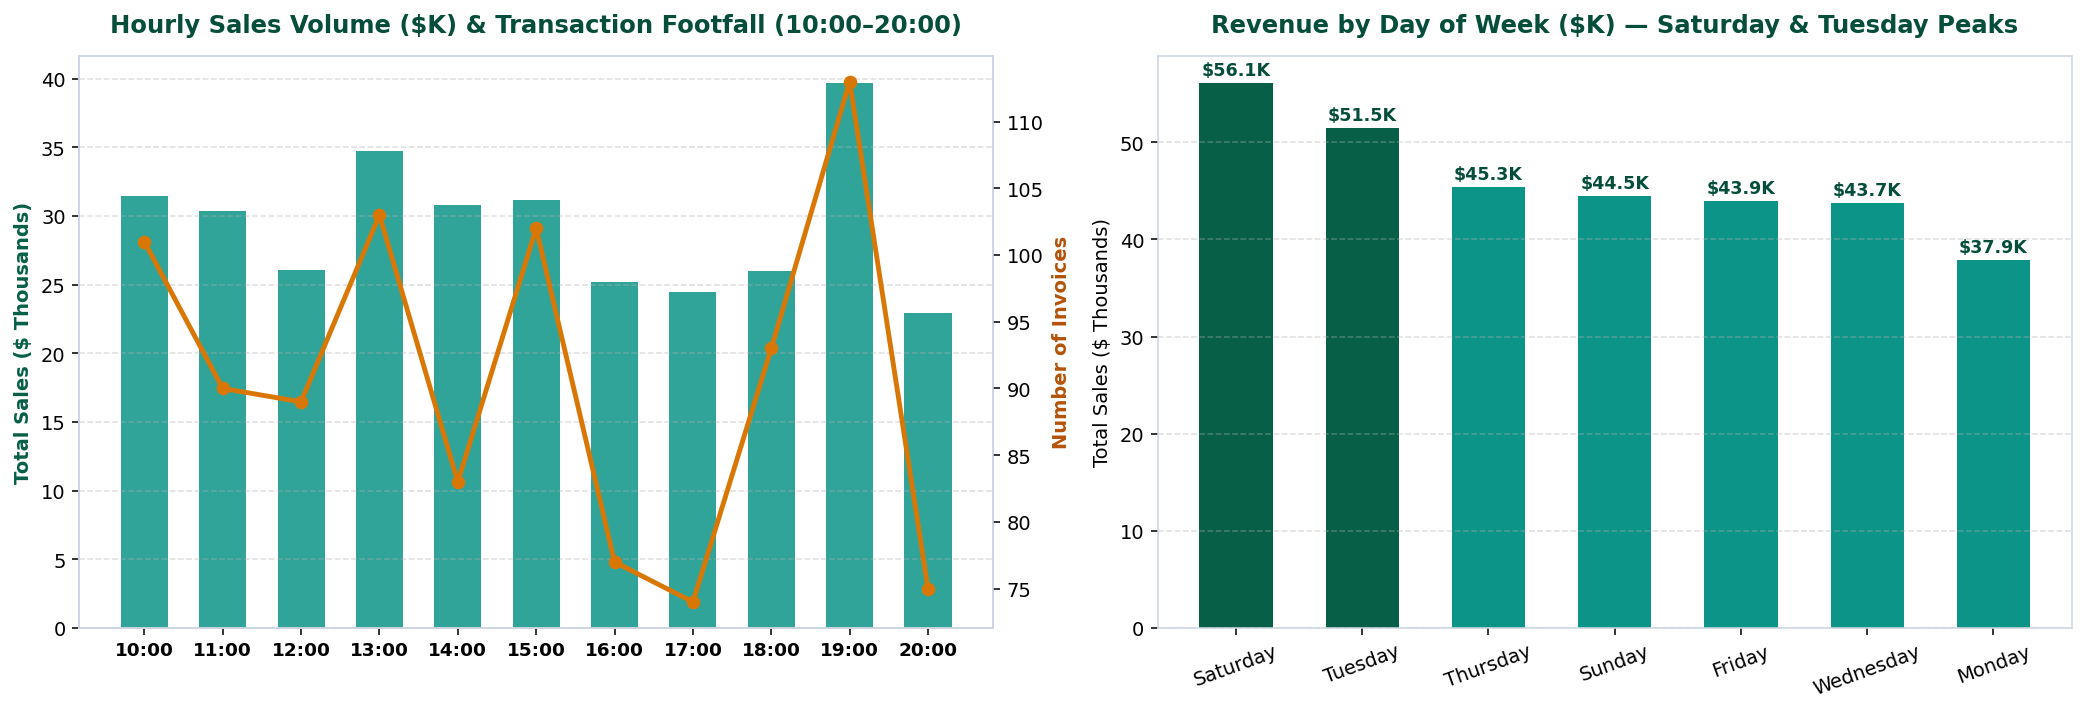

In [5]:
# Visual 3: Hourly Sales & Footfall Curve (10:00–20:00) + Day of Week Revenue


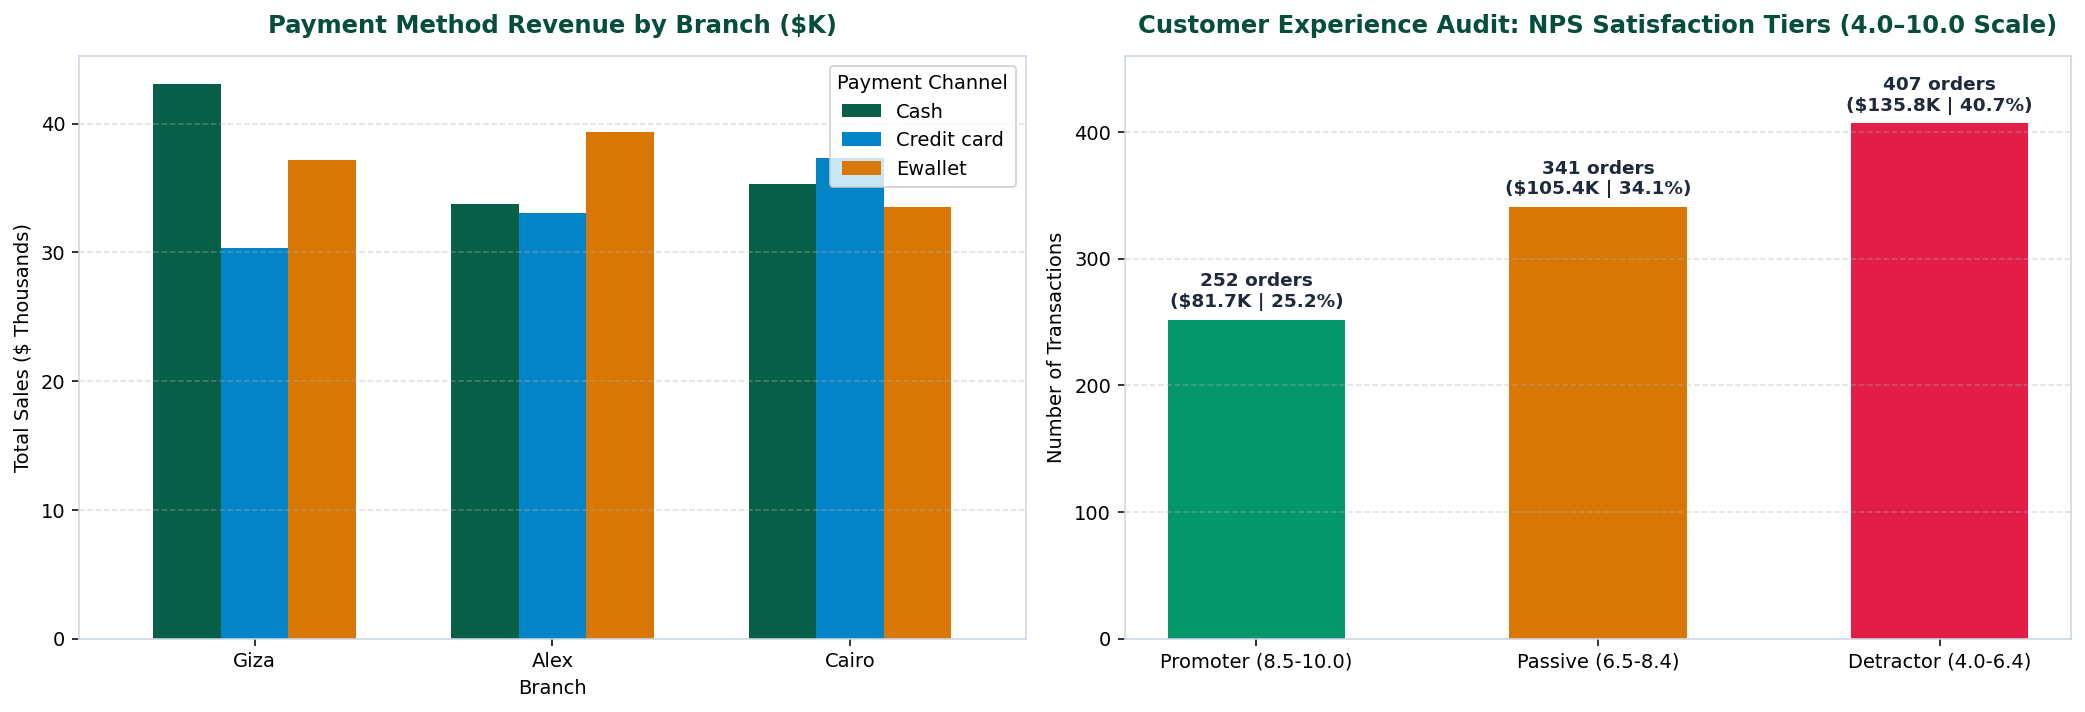

In [6]:
# Visual 4: Payment Channel Preferences by Branch + NPS Customer Satisfaction Tiers


## 4. SQLite Analytical Warehouse (`SuperMarket_Analysis.db`)
We query our 6 pre-built SQL analytical views directly from `SuperMarket_Analysis.db`.


In [7]:
conn = sqlite3.connect("SuperMarket_Analysis.db")
print("=== 1. Branch Executive KPIs (vw_branch_executive_kpis) ===")
print(pd.read_sql("SELECT * FROM vw_branch_executive_kpis", conn).to_string(index=False))

print("\n=== 2. Product Line Performance (vw_product_line_performance) ===")
print(pd.read_sql("SELECT * FROM vw_product_line_performance", conn).to_string(index=False))

print("\n=== 3. Customer Persona Analytics (vw_customer_persona_analytics) ===")
print(pd.read_sql("SELECT * FROM vw_customer_persona_analytics", conn).to_string(index=False))


=== 1. Branch Executive KPIs (vw_branch_executive_kpis) ===
Branch       City  total_invoices  total_units_sold  total_revenue  total_cogs  total_gross_profit  avg_ticket_size  avg_basket_units  avg_customer_rating  promoter_share_pct  detractor_share_pct
  Giza       Giza             328              1831     110,568.71  105,303.53            5,265.18           337.10              5.58                 7.07               27.13                38.41
  Alex Alexandria             340              1859     106,200.37  101,143.21            5,057.16           312.35              5.47                 7.03               25.29                39.12
 Cairo      Cairo             332              1820     106,197.67  101,140.64            5,057.03           319.87              5.48                 6.82               23.19                44.58

=== 2. Product Line Performance (vw_product_line_performance) ===
          Product line  transactions  units_sold  avg_unit_price  total_revenue  total_gr